# Multi-head self-attention and cross-attention

A bilingual glossary contains a source token and a word class. Two heads can consult the same memory for different attributes.

In self-attention the queries and memory come from the same sequence. Cross-attention supplies queries from a second sequence, producing a rectangular matrix. Here the head projections select two known coordinate pairs, making each preference visible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)


def attend(queries, memory):
    n_heads = 2
    width = 2
    q = queries.reshape(len(queries), n_heads, width).transpose(1, 0, 2)
    k = memory.reshape(len(memory), n_heads, width).transpose(1, 0, 2)
    w = softmax(q @ k.transpose(0, 2, 1) / np.sqrt(width))
    values = (w @ k).transpose(1, 0, 2).reshape(len(queries), -1)
    return w, values

## Trace two queries through two heads

The source tokens have separate identity and class coordinates. The example uses identity output projection after concatenation.

In [2]:
source = np.array(
    [[2.0, 0.0, 2.0, 0.0], [0.0, 2.0, 2.0, 0.0], [2.0, 0.0, 0.0, 2.0], [0.0, 2.0, 0.0, 2.0]]
)
target = np.array([[2.0, 0.0, 0.0, 2.0], [0.0, 2.0, 2.0, 0.0], [1.0, 1.0, 0.0, 2.0]])
self_w, _ = attend(source, source)
cross_w, context = attend(target, source)
rows = []
for h in range(2):
    for i, weights in enumerate(cross_w[h]):
        rows.append(
            (h + 1, i + 1, np.argmax(weights) + 1, weights.max(), -weights @ np.log(weights))
        )
assert context.shape == (3, 4) and np.allclose(cross_w.sum(-1), 1)
report(["Head", "Target query", "First maximum key", "Maximum weight", "Entropy (nats)"], rows)

,Head,Target query,First maximum key,Maximum weight,Entropy (nats)
0,1,1,1,0.4721,0.90842
1,1,2,2,0.4721,0.90842
2,1,3,1,0.2500,1.38629
3,2,1,3,0.4721,0.90842
4,2,2,1,0.4721,0.90842
5,2,3,3,0.4721,0.90842


## Compare square and rectangular attention

Rows denote queries and columns denote source tokens. Ties are expected because each coordinate pair is shared by two records.

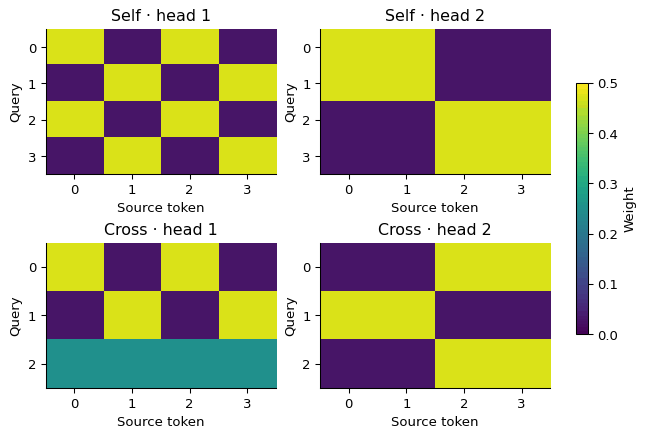

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(6.7, 4.5), layout="constrained")
for i, maps in enumerate([self_w, cross_w]):
    for j, w in enumerate(maps):
        ax = axes[i, j]
        im = ax.imshow(w, vmin=0, vmax=0.5, cmap="viridis", aspect="auto")
        ax.set(
            title=f"{['Self','Cross'][i]} · head {j+1}",
            xlabel="Source token",
            ylabel="Query",
            xticks=range(4),
            yticks=range(len(w)),
        )
fig.colorbar(im, ax=axes, label="Weight", shrink=0.7)
plt.show()

## Interpreting the result

An attention head reads only the coordinates selected by its projections in this construction. Learnt projections can mix coordinates before the dot product.

## Exercise

Swap the target rows. Verify that the cross-attention output follows the permutation and that the self-attention map stays fixed.

## References

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)